In [42]:
#Imports
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
sns.set_theme(style="whitegrid")


In [43]:
#Define dataset paths
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"

IMAGE_DIRS = [
    DATA_DIR / "HAM10000_images_part_1",
    DATA_DIR / "HAM10000_images_part_2"
]

METADATA_PATH = DATA_DIR / "HAM10000_metadata.csv"

In [44]:
#Load metadata
df = pd.read_csv(METADATA_PATH)

In [45]:
#Dataset overview
print("Dataset shape:", df.shape)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("Memory usage:")
print(df.memory_usage(deep=True).sum() / 1024**2, "MB")

Dataset shape: (10015, 7)
Number of rows: 10015
Number of columns: 7
Memory usage:
3.3169517517089844 MB


In [46]:
#Inspect the schema
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  str    
 1   image_id      10015 non-null  str    
 2   dx            10015 non-null  str    
 3   dx_type       10015 non-null  str    
 4   age           9958 non-null   float64
 5   sex           10015 non-null  str    
 6   localization  10015 non-null  str    
dtypes: float64(1), str(6)
memory usage: 547.8 KB


In [47]:
#Inspect sample records
display(df.head())

,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [48]:
#Missing values
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": df.isnull().mean() * 100
})

display(missing)

,missing_count,missing_percentage
lesion_id,0,0.000000
image_id,0,0.000000
dx,0,0.000000
dx_type,0,0.000000
age,57,0.569146
sex,0,0.000000
localization,0,0.000000


In [49]:
#Duplicate records
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate image IDs:", df["image_id"].duplicated().sum())

Duplicate rows: 0
Duplicate image IDs: 0


In [50]:
class_counts = df['dx'].value_counts()
print("Class Distribution:\n")
print(class_counts)
print(f"\nTotal images: {len(df)}")

# Class names mapping
class_names = {
    'akiec': 'Actinic keratoses',
    'bcc': 'Basal cell carcinoma',
    'bkl': 'Benign keratosis-like',
    'df': 'Dermatofibroma',
    'mel': 'Melanoma',
    'nv': 'Melanocytic nevi',
    'vasc': 'Vascular lesions'
}

# Detailed breakdown with percentages
print("\nDetailed Class Breakdown:")
for code in class_counts.index:
    count = class_counts[code]
    pct = (count / len(df)) * 100
    print(f"  {code:6s}: {count:5d} images ({pct:5.1f}%) - {class_names[code]}")

# Calculate imbalance ratio
imbalance_ratio = class_counts.max() / class_counts.min()
print(f"\nClass Imbalance Ratio: {imbalance_ratio:.1f}:1")

Class Distribution:

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

Total images: 10015

Detailed Class Breakdown:
  nv    :  6705 images ( 66.9%) - Melanocytic nevi
  mel   :  1113 images ( 11.1%) - Melanoma
  bkl   :  1099 images ( 11.0%) - Benign keratosis-like
  bcc   :   514 images (  5.1%) - Basal cell carcinoma
  akiec :   327 images (  3.3%) - Actinic keratoses
  vasc  :   142 images (  1.4%) - Vascular lesions
  df    :   115 images (  1.1%) - Dermatofibroma

Class Imbalance Ratio: 58.3:1


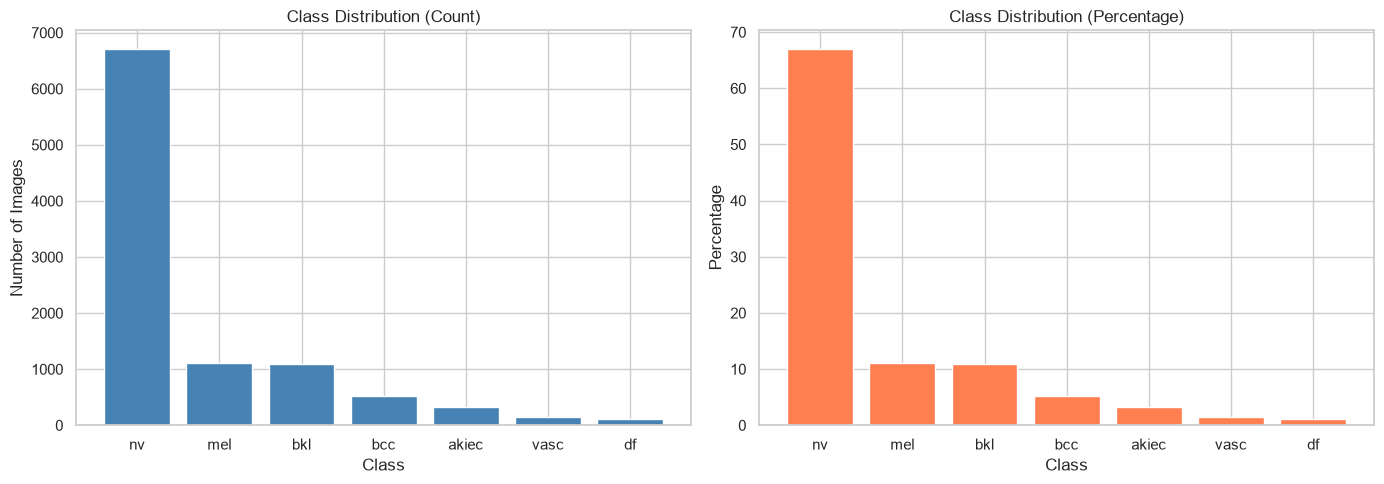

In [51]:
# Visualize class distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count plot
axes[0].bar(class_counts.index, class_counts.values, color='steelblue')
axes[0].set_title('Class Distribution (Count)', fontsize=12)
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Number of Images')

# Percentage plot
class_pct = (class_counts / len(df)) * 100
axes[1].bar(class_pct.index, class_pct.values, color='coral')
axes[1].set_title('Class Distribution (Percentage)', fontsize=12)
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Percentage')

plt.tight_layout()
plt.show()

In [52]:
# CRITICAL: Analyze lesion_id for proper splitting
print("Lesion ID Analysis:")
print(f"Total images: {len(df)}")
print(f"Unique lesion IDs: {df['lesion_id'].nunique()}")

# Images per lesion
images_per_lesion = df.groupby("lesion_id").size()
print("\nImages per lesion statistics:")
print(images_per_lesion.describe())

# Lesions with multiple images
multi_image_lesions = images_per_lesion[images_per_lesion > 1]
print(f"\nLesions with multiple images: {len(multi_image_lesions)}")
print(f"Single-image lesions: {len(images_per_lesion) - len(multi_image_lesions)}")

# Distribution of images per lesion
print("\nDistribution of images per lesion:")
print(images_per_lesion.value_counts().sort_index())

# IMPORTANT: Check if any lesion has multiple class labels
lesion_class_count = df.groupby("lesion_id")["dx"].nunique()
multi_class_lesions = lesion_class_count[lesion_class_count > 1]
print(f"\nLesions with multiple class labels: {len(multi_class_lesions)}")

if len(multi_class_lesions) > 0:
    print("WARNING: These lesions have inconsistent labels!")
    for lesion_id in multi_class_lesions.head(3).index:
        classes = df[df["lesion_id"] == lesion_id]["dx"].unique()
        print(f"  {lesion_id}: {classes}")
else:
    print("Good: All lesions have consistent class labels")

Lesion ID Analysis:
Total images: 10015
Unique lesion IDs: 7470

Images per lesion statistics:
count    7470.000000
mean        1.340696
std         0.633970
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         6.000000
dtype: float64

Lesions with multiple images: 1956
Single-image lesions: 5514

Distribution of images per lesion:
1    5514
2    1423
3     490
4      34
5       5
6       4
Name: count, dtype: int64

Lesions with multiple class labels: 0
Good: All lesions have consistent class labels


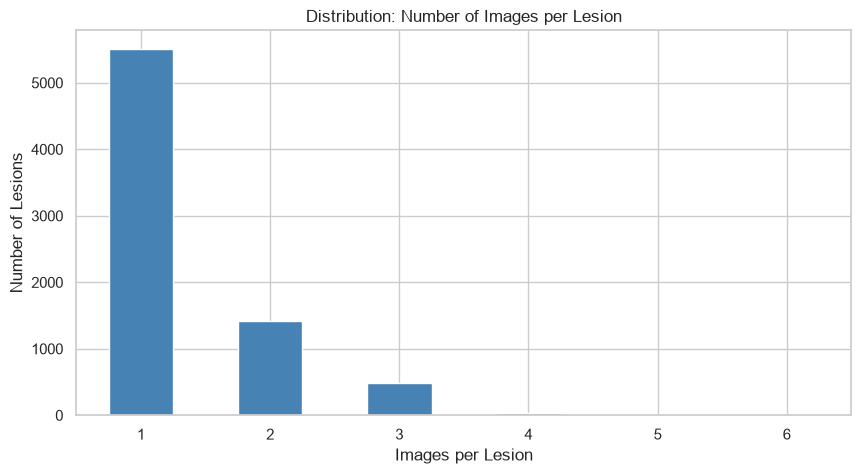


Example lesions with multiple images:

HAM_0000000 (2 images):
          image_id  dx   age   sex
9187  ISIC_0028498  nv  60.0  male
9188  ISIC_0025346  nv  60.0  male

HAM_0000002 (3 images):
          image_id   dx   age     sex
1660  ISIC_0033848  mel  65.0  female
1661  ISIC_0032622  mel  65.0  female
1662  ISIC_0034246  mel  65.0  female

HAM_0000005 (4 images):
          image_id     dx   age     sex
9898  ISIC_0025577  akiec  75.0  female
9899  ISIC_0030591  akiec  75.0  female
9900  ISIC_0024579  akiec  75.0  female
9901  ISIC_0029638  akiec  75.0  female


In [53]:
# Visualize images per lesion
plt.figure(figsize=(10, 5))
images_per_lesion.value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Distribution: Number of Images per Lesion')
plt.xlabel('Images per Lesion')
plt.ylabel('Number of Lesions')
plt.xticks(rotation=0)
plt.show()

# Show examples of lesions with multiple images
print("\nExample lesions with multiple images:")
for lesion_id in multi_image_lesions.head(3).index:
    subset = df[df['lesion_id'] == lesion_id]
    print(f"\n{lesion_id} ({len(subset)} images):")
    print(subset[['image_id', 'dx', 'age', 'sex']].to_string())

In [54]:
# Verify image files exist
part1_dir = DATA_DIR / "HAM10000_images_part_1"
part2_dir = DATA_DIR / "HAM10000_images_part_2"

# Get all image files
part1_images = set(f.stem for f in part1_dir.glob("*.jpg")) if part1_dir.exists() else set()
part2_images = set(f.stem for f in part2_dir.glob("*.jpg")) if part2_dir.exists() else set()

all_images = part1_images | part2_images

print(f"Images in part_1: {len(part1_images)}")
print(f"Images in part_2: {len(part2_images)}")
print(f"Total images found: {len(all_images)}")
print(f"Expected from metadata: {len(df)}")

# Check for overlap between folders
overlap = part1_images & part2_images
print(f"Images in both folders: {len(overlap)}")

# Verify all metadata images exist
metadata_images = set(df['image_id'])
missing_images = metadata_images - all_images
extra_images = all_images - metadata_images

print(f"\nMissing images: {len(missing_images)}")
print(f"Extra images on disk: {len(extra_images)}")

if missing_images:
    print(f"\nFirst 5 missing: {list(missing_images)[:5]}")
if extra_images:
    print(f"\nFirst 5 extra: {list(extra_images)[:5]}")

Images in part_1: 5000
Images in part_2: 5015
Total images found: 10015
Expected from metadata: 10015
Images in both folders: 0

Missing images: 0
Extra images on disk: 0


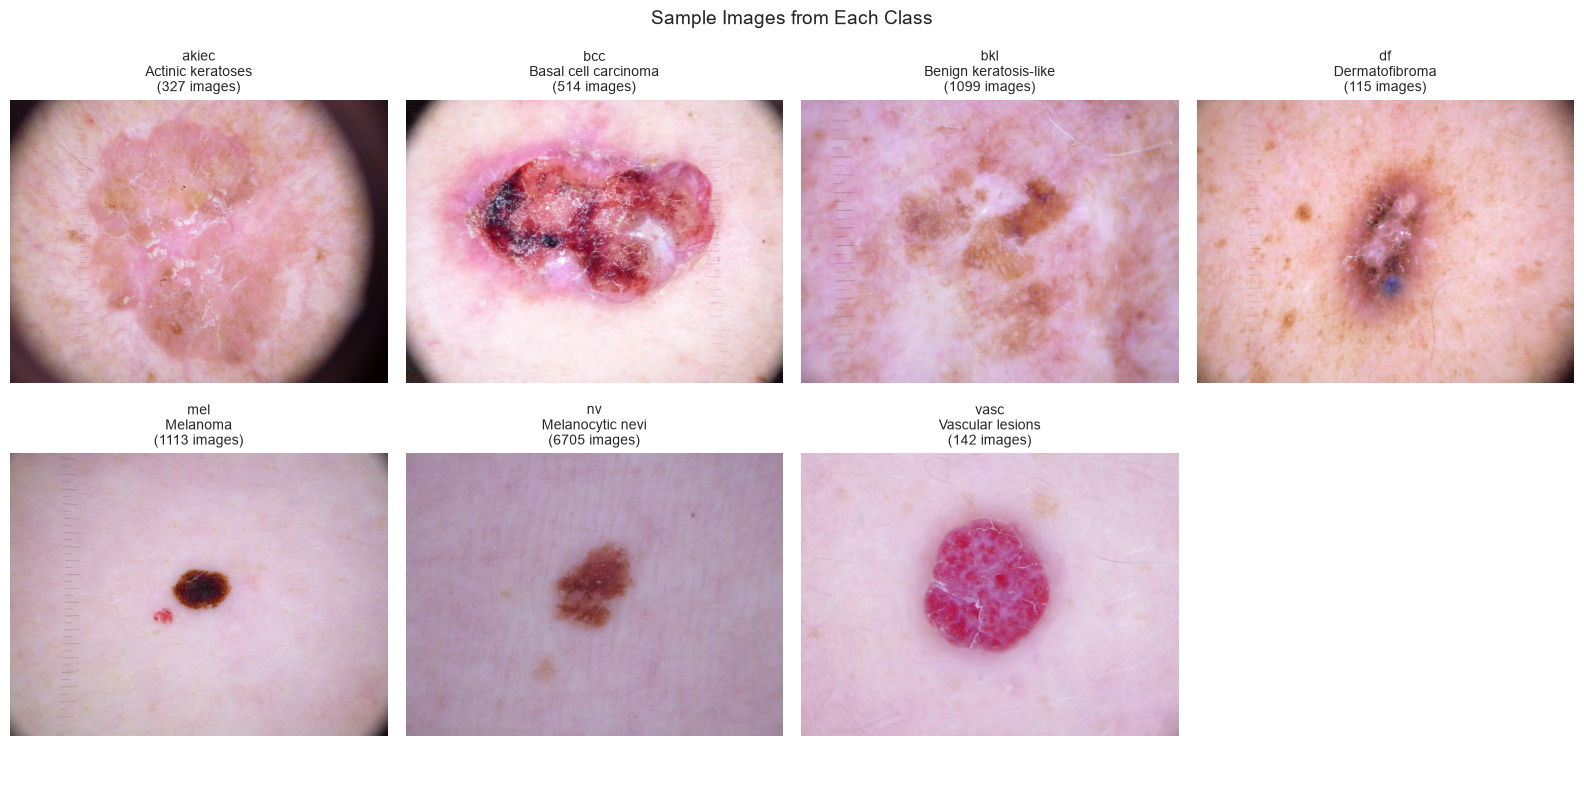

In [55]:
#Display Sample Images from Each Class


# Function to find image path
def get_image_path(image_id):
    img_name = f"{image_id}.jpg"
    path1 = part1_dir / img_name
    path2 = part2_dir / img_name
    if path1.exists():
        return path1
    elif path2.exists():
        return path2
    return None

# Show sample images from each class
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

classes = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

for idx, cls in enumerate(classes):
    # Get first image of this class
    sample = df[df['dx'] == cls].iloc[0]
    img_path = get_image_path(sample['image_id'])
    
    if img_path:
        img = Image.open(img_path)
        axes[idx].imshow(img)
        axes[idx].set_title(f"{cls}\n{class_names[cls]}\n({class_counts[cls]} images)", fontsize=10)
        axes[idx].axis('off')
    else:
        axes[idx].text(0.5, 0.5, "Image not found", ha='center')
        axes[idx].set_title(cls)

axes[7].axis('off')  # Hide the 8th subplot
plt.suptitle('Sample Images from Each Class', fontsize=14)
plt.tight_layout()
plt.show()

In [56]:
#Demographic Analysis

# Analyze age distribution
print("Age Statistics:")
print(df['age'].describe())

# Age by class
print("\nAge by Class:")
age_by_class = df.groupby('dx')['age'].agg(['mean', 'median', 'std', 'count'])
print(age_by_class.round(1))

# Sex distribution
print("\nSex Distribution:")
print(df['sex'].value_counts())
print(df['sex'].value_counts(normalize=True).round(3) * 100)

# Localization distribution
print("\nLocalization Distribution (top 10):")
print(df['localization'].value_counts().head(10))

Age Statistics:
count    9958.000000
mean       51.863828
std        16.968614
min         0.000000
25%        40.000000
50%        50.000000
75%        65.000000
max        85.000000
Name: age, dtype: float64

Age by Class:
       mean  median   std  count
dx                              
akiec  66.5    70.0  11.5    327
bcc    66.8    70.0  13.7    514
bkl    64.3    65.0  14.1   1089
df     53.0    50.0  13.6    115
mel    60.7    60.0  15.2   1111
nv     46.5    45.0  15.2   6660
vasc   51.4    55.0  21.6    142

Sex Distribution:
sex
male       5406
female     4552
unknown      57
Name: count, dtype: int64
sex
male       54.0
female     45.5
unknown     0.6
Name: proportion, dtype: float64

Localization Distribution (top 10):
localization
back               2192
lower extremity    2077
trunk              1404
upper extremity    1118
abdomen            1022
face                745
chest               407
foot                319
unknown             234
neck                168
Name: 

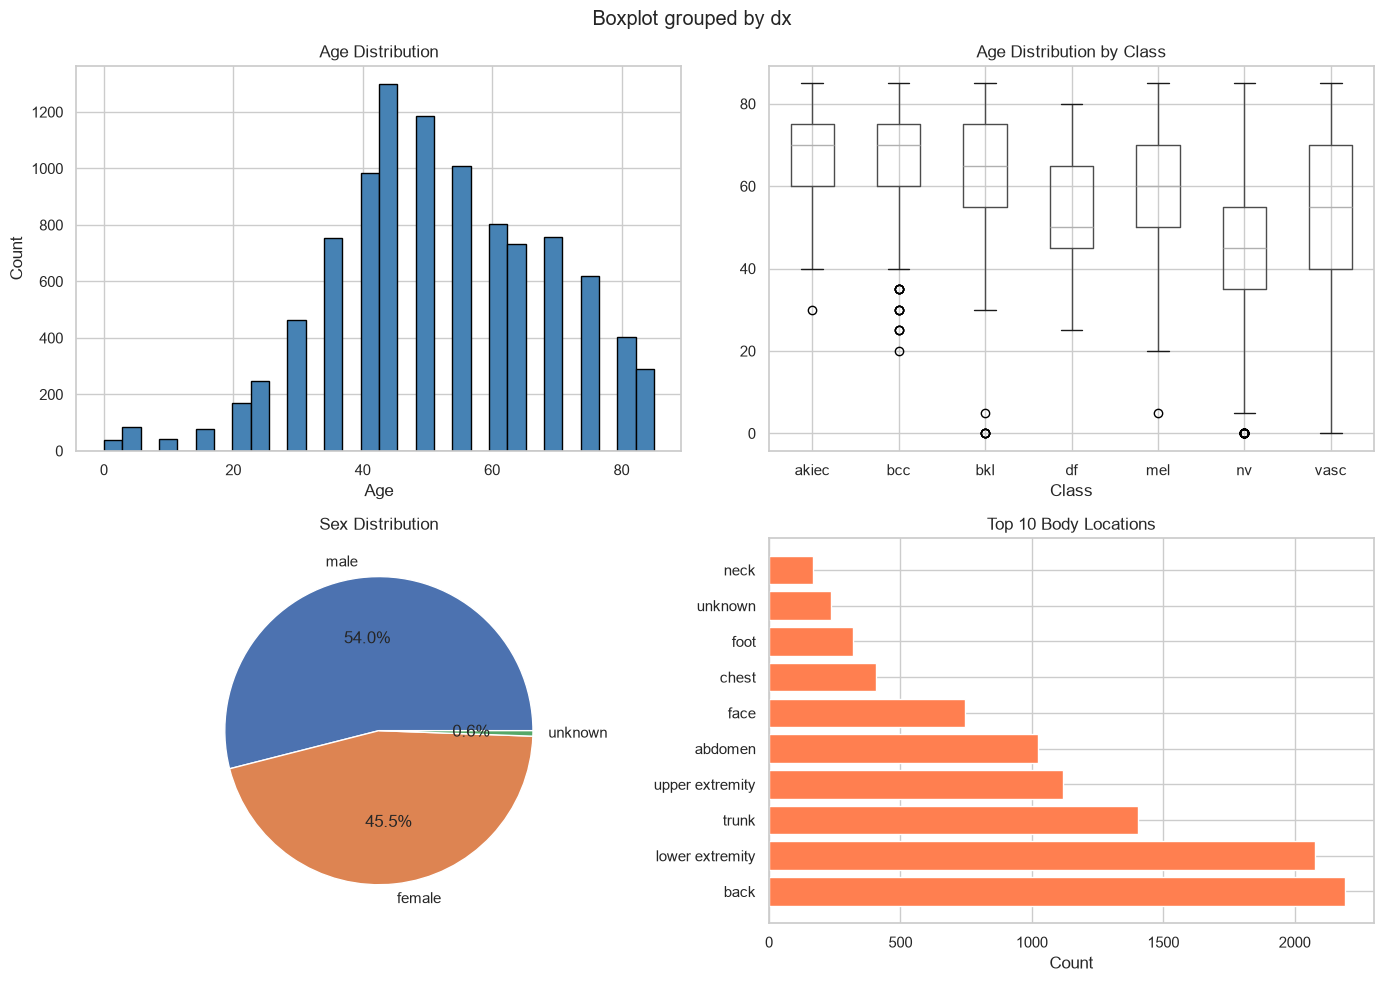

In [57]:
# Visualize demographics
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Age distribution
axes[0, 0].hist(df['age'].dropna(), bins=30, color='steelblue', edgecolor='black')
axes[0, 0].set_title('Age Distribution')
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Count')

# Age by class
df.boxplot(column='age', by='dx', ax=axes[0, 1])
axes[0, 1].set_title('Age Distribution by Class')
axes[0, 1].set_xlabel('Class')

# Sex distribution
sex_counts = df['sex'].value_counts()
axes[1, 0].pie(sex_counts.values, labels=sex_counts.index, autopct='%1.1f%%')
axes[1, 0].set_title('Sex Distribution')

# Localization (top 10)
top_locs = df['localization'].value_counts().head(10)
axes[1, 1].barh(top_locs.index, top_locs.values, color='coral')
axes[1, 1].set_title('Top 10 Body Locations')
axes[1, 1].set_xlabel('Count')

plt.tight_layout()
plt.show()

In [58]:
# Complete dataset summary
print("=" * 60)
print("HAM10000 DATASET SUMMARY")
print("=" * 60)

print(f"\nDataset Overview:")
print(f"  Total images: {len(df):,}")
print(f"  Unique lesions: {df['lesion_id'].nunique():,}")
print(f"  Classes: {df['dx'].nunique()}")
print(f"  Class imbalance ratio: {class_counts.max()/class_counts.min():.1f}:1")

print(f"\nClass Distribution:")
for code in class_counts.index:
    count = class_counts[code]
    pct = (count / len(df)) * 100
    print(f"  {code:6s}: {count:5,} ({pct:5.1f}%) - {class_names[code]}")

print(f"\nData Quality:")
print(f"  ✓ Missing values (age only): {df['age'].isnull().sum()} ({df['age'].isnull().mean()*100:.1f}%)")
print(f"  ✓ Duplicate rows: {df.duplicated().sum()}")
print(f"  ✓ Duplicate image IDs: {df['image_id'].duplicated().sum()}")
print(f"  ✓ Images missing from disk: {len(missing_images)}")
print(f"  ✓ Lesions with multiple images: {len(multi_image_lesions)}")
print(f"  ✓ Lesions with inconsistent labels: {len(multi_class_lesions)}")

print(f"\nDemographics:")
print(f"  Mean age: {df['age'].mean():.1f} ± {df['age'].std():.1f}")
print(f"  Male: {(df['sex']=='male').sum():,} ({(df['sex']=='male').mean()*100:.1f}%)")
print(f"  Female: {(df['sex']=='female').sum():,} ({(df['sex']=='female').mean()*100:.1f}%)")

print("\n" + "=" * 60)
print("Key Takeaways:")
print("=" * 60)
print("1. SEVERE CLASS IMBALANCE: nv dominates (67%), mel is rare (11%)")
print("2. MUST split by lesion_id, not by image, to prevent data leakage")
print("3. 57 missing age values - handle appropriately")
print("4. Focal loss recommended due to class imbalance")

HAM10000 DATASET SUMMARY

Dataset Overview:
  Total images: 10,015
  Unique lesions: 7,470
  Classes: 7
  Class imbalance ratio: 58.3:1

Class Distribution:
  nv    : 6,705 ( 66.9%) - Melanocytic nevi
  mel   : 1,113 ( 11.1%) - Melanoma
  bkl   : 1,099 ( 11.0%) - Benign keratosis-like
  bcc   :   514 (  5.1%) - Basal cell carcinoma
  akiec :   327 (  3.3%) - Actinic keratoses
  vasc  :   142 (  1.4%) - Vascular lesions
  df    :   115 (  1.1%) - Dermatofibroma

Data Quality:
  ✓ Missing values (age only): 57 (0.6%)
  ✓ Duplicate rows: 0
  ✓ Duplicate image IDs: 0
  ✓ Images missing from disk: 0
  ✓ Lesions with multiple images: 1956
  ✓ Lesions with inconsistent labels: 0

Demographics:
  Mean age: 51.9 ± 17.0
  Male: 5,406 (54.0%)
  Female: 4,552 (45.5%)

Key Takeaways:
1. SEVERE CLASS IMBALANCE: nv dominates (67%), mel is rare (11%)
2. MUST split by lesion_id, not by image, to prevent data leakage
3. 57 missing age values - handle appropriately
4. Focal loss recommended due to class 

In [59]:
# Save summary to file
summary = {
    'total_images': len(df),
    'unique_lesions': df['lesion_id'].nunique(),
    'class_distribution': class_counts.to_dict(),
    'imbalance_ratio': class_counts.max() / class_counts.min(),
    'multi_image_lesions': len(multi_image_lesions),
    'missing_images': len(missing_images),
    'mean_age': df['age'].mean(),
    'missing_age': df['age'].isnull().sum()
}

# Save as CSV for reference
class_counts.to_frame('count').to_csv('../data/class_distribution.csv')
print("Summary saved to ../data/class_distribution.csv")

Summary saved to ../data/class_distribution.csv
